# 2D crosswell straight-ray tomography

This notebook uses `simpeg_seismic.traveltime.SimulationStraightRay` to simulate first-arrival
traveltimes between two boreholes, then inverts them for velocity.

In straight-ray tomography, the traveltime of each source-receiver pair is the
integral of slowness $s = 1/v$ along the straight line between them:

$$
t_i = \int_{\text{ray}_i} s(\mathbf{x})\, dl
\quad\Rightarrow\quad
\mathbf{d} = \mathbf{G}\,\mathbf{s},
$$

where $G_{ij}$ is the length of ray $i$ in cell $j$. Working in slowness makes
the problem linear.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import discretize
from simpeg import (
    maps,
    data_misfit,
    regularization,
    optimization,
    inverse_problem,
    inversion,
    directives,
)

from simpeg_seismic import traveltime

## Mesh and true model

The boreholes are 60 m apart and 80 m deep, and the mesh has 2 m cells. The
true model is a 2500 m/s background with a slow layer and a fast inclusion.

In [2]:
mesh = discretize.TensorMesh([np.full(30, 2.0), np.full(40, 2.0)], origin=[0.0, -80.0])

x, z = mesh.cell_centers.T
velocity_true = np.full(mesh.n_cells, 2500.0)
velocity_true[(z < -25) & (z > -35)] = 2000.0
velocity_true[(x - 40) ** 2 + (z + 60) ** 2 < 8**2] = 3200.0

slowness_true = 1.0 / velocity_true
mesh

TensorMesh: 1,200 cells

                      MESH EXTENT             CELL WIDTH      FACTOR
  dir    nC        min           max         min       max      max
  ---   ---  ---------------------------  ------------------  ------
   x     30          0.00         60.00      2.00      2.00    1.00
   y     40        -80.00          0.00      2.00      2.00    1.00

## Survey

There are 20 sources in the left borehole and 39 receivers in the right one,
which gives 780 traveltimes. A `PointSource` takes a list of receivers, and
each `Traveltime` receiver can hold many locations.

In [3]:
source_depths = np.linspace(-78, -2, 20)
receiver_depths = np.linspace(-78, -2, 39)
receiver_locations = np.c_[np.full_like(receiver_depths, 60.0), receiver_depths]

source_list = [
    traveltime.sources.PointSource(
        receiver_list=[traveltime.receivers.Traveltime(receiver_locations)],
        location=np.r_[0.0, depth],
    )
    for depth in source_depths
]
survey = traveltime.Survey(source_list)
print(f"{survey.nD} traveltimes")

780 traveltimes


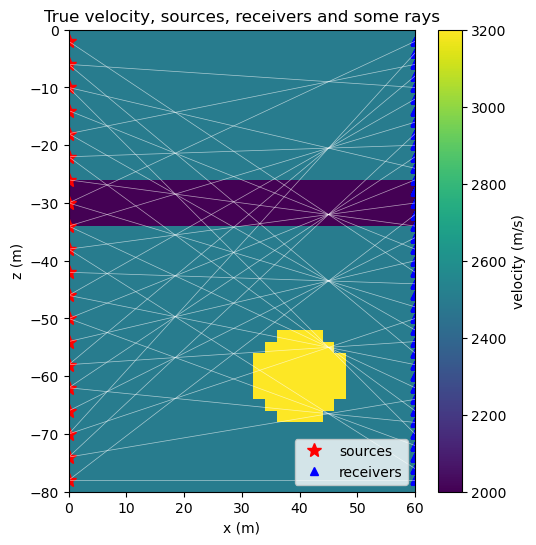

In [4]:
fig, ax = plt.subplots(figsize=(6, 6))
out = mesh.plot_image(velocity_true, ax=ax, pcolor_opts={"cmap": "viridis"})
plt.colorbar(out[0], ax=ax, label="velocity (m/s)")
survey.plot(ax=ax, plot_rays=False)
src, rx = survey.ray_endpoints
for i in range(0, survey.nD, 23):  # a subset of the rays, for legibility
    ax.plot(*np.c_[src[i], rx[i]], "w-", lw=0.5, alpha=0.6)
ax.set_aspect("equal")
ax.set_xlabel("x (m)")
ax.set_ylabel("z (m)")
ax.set_title("True velocity, sources, receivers and some rays")
ax.legend(loc="lower right");

## Forward simulation

The simulation's `G` matrix is built the first time it is needed and then
cached. The sum of each column of `G` is the total ray length in that cell,
which is a quick way to see where the data actually constrain the model.

G: 780 x 1200, 31,276 nonzeros


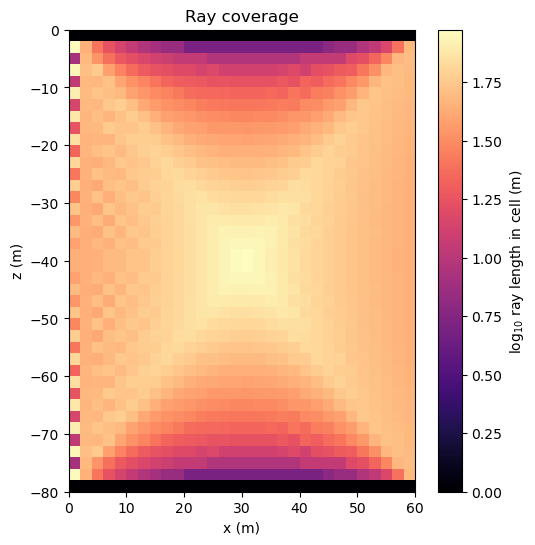

In [5]:
simulation = traveltime.SimulationStraightRay(
    mesh, survey=survey, slownessMap=maps.IdentityMap(mesh)
)

G = simulation.G
print(f"G: {G.shape[0]} x {G.shape[1]}, {G.nnz:,} nonzeros")

fig, ax = plt.subplots(figsize=(6, 6))
coverage = np.asarray(G.sum(axis=0)).ravel()
out = mesh.plot_image(np.log10(coverage), ax=ax, pcolor_opts={"cmap": "magma"})
plt.colorbar(out[0], ax=ax, label="log$_{10}$ ray length in cell (m)")
ax.set_aspect("equal")
ax.set_xlabel("x (m)")
ax.set_ylabel("z (m)")
ax.set_title("Ray coverage");

Next, simulate data with 0.1 ms of Gaussian noise. The traveltimes are
about 20-35 ms, so this is roughly 0.3-0.5% noise.

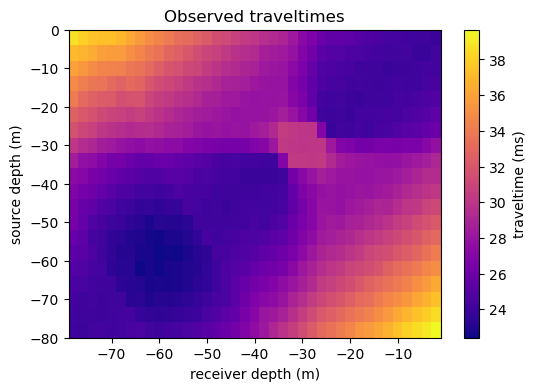

In [6]:
data_obs = simulation.make_synthetic_data(
    slowness_true, relative_error=0.0, noise_floor=1e-4, add_noise=True, random_seed=42
)

fig, ax = plt.subplots(figsize=(6, 4))
t = data_obs.dobs.reshape(len(source_depths), len(receiver_depths)) * 1e3
out = ax.pcolormesh(receiver_depths, source_depths, t, cmap="plasma")
plt.colorbar(out, ax=ax, label="traveltime (ms)")
ax.set_xlabel("receiver depth (m)")
ax.set_ylabel("source depth (m)")
ax.set_title("Observed traveltimes");

## Inversion

We invert for slowness with a smoothness regularization. The starting and
reference model is a homogeneous slowness equal to the average apparent
slowness of the data (total traveltime divided by total ray length). Because
the problem is linear, each Gauss-Newton step only needs to solve one linear
system (here approximately, with a few CG iterations). We cool $\beta$ until
the data misfit reaches its target, $\phi_d \approx N_d$.

In [7]:
ray_lengths = np.asarray(G.sum(axis=1)).ravel()
s0 = data_obs.dobs.sum() / ray_lengths.sum()
m0 = np.full(mesh.n_cells, s0)
print(f"starting velocity: {1 / s0:.0f} m/s")

dmis = data_misfit.L2DataMisfit(data=data_obs, simulation=simulation)
reg = regularization.WeightedLeastSquares(
    mesh, reference_model=m0, alpha_s=1e-3, alpha_x=1.0, alpha_y=1.0
)
opt = optimization.InexactGaussNewton(maxIter=20, cg_maxiter=50)
inv_prob = inverse_problem.BaseInvProblem(dmis, reg, opt)

directive_list = [
    directives.BetaEstimate_ByEig(beta0_ratio=10.0, random_seed=0),
    directives.BetaSchedule(coolingFactor=2.0, coolingRate=1),
    directives.TargetMisfit(chifact=1.0),
]
inv = inversion.BaseInversion(inv_prob, directiveList=directive_list)
slowness_rec = inv.run(m0)

INFO: 
simpeg.InvProblem is setting bfgsH0 to the inverse of the reg.deriv2.
using the default solver Mumps with the 'is_symmetric=True` option set.



INFO: Directive TargetMisfit: Target data misfit is 780.0


starting velocity: 2444 m/s

Running inversion with SimPEG v0.25.2
============================ Inexact Gauss Newton ============================
  #     beta     phi_d     phi_m       f      |proj(x-g)-x|  LS    Comment   
-----------------------------------------------------------------------------
   0  5.77e+11  1.51e+05  0.00e+00  1.51e+05                                 
   1  5.77e+11  2.90e+04  3.13e-08  4.71e+04    3.07e+08      0              


   2  2.89e+11  1.98e+04  5.37e-08  3.53e+04    4.73e+07      0   Skip BFGS  
   3  1.44e+11  1.27e+04  8.82e-08  2.55e+04    3.45e+07      0   Skip BFGS  
   4  7.22e+10  7.61e+03  1.38e-07  1.76e+04    2.62e+07      0   Skip BFGS  


   5  3.61e+10  4.41e+03  2.00e-07  1.16e+04    1.86e+07      0   Skip BFGS  
   6  1.80e+10  2.56e+03  2.71e-07  7.44e+03    1.28e+07      0   Skip BFGS  
   7  9.02e+09  1.53e+03  3.50e-07  4.68e+03    8.56e+06      0   Skip BFGS  


   8  4.51e+09  9.33e+02  4.42e-07  2.92e+03    5.56e+06      0   Skip BFGS  
   9  2.25e+09  5.84e+02  5.49e-07  1.82e+03    3.57e+06      0   Skip BFGS  
------------------------- STOP! -------------------------
1 : |fc-fOld| = 1.0733e+02 <= tolF*(1+|f0|) = 1.5083e+04
1 : |xc-x_last| = 6.9702e-05 <= tolX*(1+|x0|) = 1.0142e-01
0 : |proj(x-g)-x|    = 3.5657e+06 <= tolG          = 1.0000e-01
0 : |proj(x-g)-x|    = 3.5657e+06 <= 1e3*eps       = 1.0000e-02
0 : maxIter   =      20    <= iter          =      9
------------------------- DONE! -------------------------


## Results

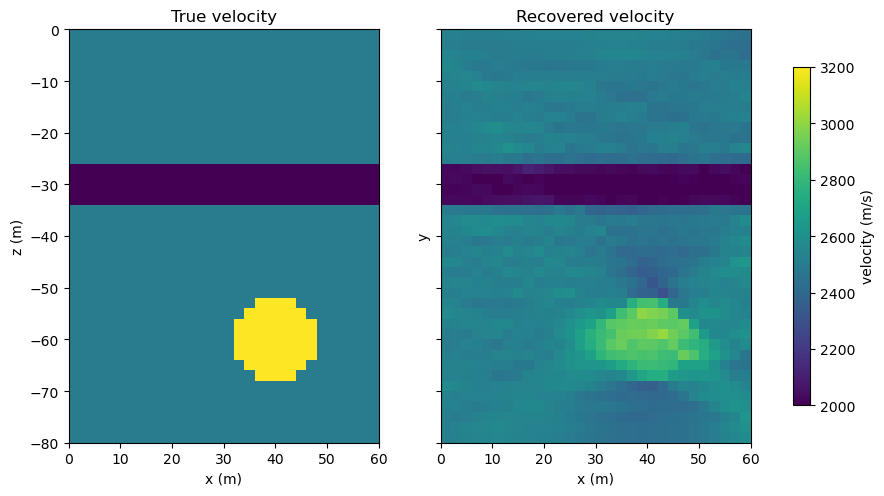

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5), sharey=True)
clim = (velocity_true.min(), velocity_true.max())
for ax, v, title in zip(
    axes, [velocity_true, 1.0 / slowness_rec], ["True velocity", "Recovered velocity"]
):
    out = mesh.plot_image(v, ax=ax, clim=clim, pcolor_opts={"cmap": "viridis"})
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")
    ax.set_title(title)
axes[0].set_ylabel("z (m)")
plt.colorbar(out[0], ax=axes, label="velocity (m/s)", shrink=0.8);

The slow layer is well recovered: many rays pass through it at a range of
angles. The fast inclusion is in the right place but smeared, mostly
horizontally. There are no vertical rays in a crosswell geometry, so
horizontal resolution is poor. Its peak velocity is also too low, as expected
from a smooth inversion.

As a check, the normalized residuals should look like standard normal noise.

phi_d = 584 for 780 data


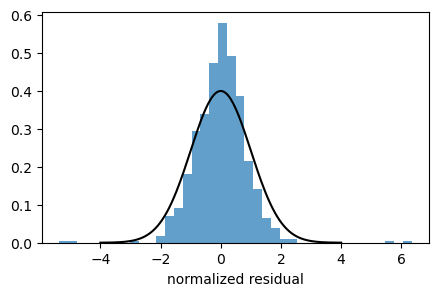

In [9]:
residual = (simulation.dpred(slowness_rec) - data_obs.dobs) / data_obs.standard_deviation
print(f"phi_d = {np.sum(residual**2):.0f} for {survey.nD} data")

fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(residual, bins=40, density=True, alpha=0.7)
xx = np.linspace(-4, 4, 200)
ax.plot(xx, np.exp(-(xx**2) / 2) / np.sqrt(2 * np.pi), "k")
ax.set_xlabel("normalized residual");